# Payment Risk Workbench — Exploration

Start by checking that this notebook uses the project environment.

In [18]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px

print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
assert Path(sys.prefix).name == ".venv", "Select this project's .venv/bin/python kernel."
print("Environment ready.")

Python: 3.12.15
Interpreter: /Users/tferrer-mbp/reemployment/projects/01-payment-risk-workbench/.venv/bin/python
Environment ready.


In [19]:
from pathlib import Path
import pandas as pd

# Locate the raw data from the project root or notebooks directory.
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

files = sorted((root / "data" / "raw").glob("creditcard_*.csv"))
assert len(files) == 5, f"Expected 5 CSV files, found {len(files)}"

# Combine the five parts in their original order.
df = pd.concat([pd.read_csv(file) for file in files], ignore_index=True)

print(f"{df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

284,807 rows × 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [20]:
# Data overview: types, missing values, and exact duplicates
df.info()

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100),
}).sort_values("missing_count", ascending=False)
display(missing)

duplicate_count = df.duplicated().sum()
print(f"Exact duplicate rows beyond the first occurrence: {duplicate_count:,}")
print(f"Duplicate share: {duplicate_count / len(df):.2%}")
# Keep all records while we investigate why duplicates occur.

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

,missing_count,missing_pct
Time,0,0.0
V16,0,0.0
Amount,0,0.0
V28,0,0.0
V27,0,0.0
V26,0,0.0
V25,0,0.0
V24,0,0.0
V23,0,0.0
V22,0,0.0


Exact duplicate rows beyond the first occurrence: 1,081
Duplicate share: 0.38%


### Initial findings

- The dataset contains 284,807 transactions and 31 numeric columns: 30 float columns and the integer target, `Class`.
- No column contains missing values, so missing-value imputation is unnecessary for this snapshot.
- There are 1,081 exact duplicate rows beyond their first occurrence (0.38% of the dataset). Keep them for now and investigate their origin and overlap across evaluation splits before deciding how to handle them.
- Next: inspect the `Class` counts and fraud prevalence. Accuracy alone may be misleading when the classes are imbalanced.

## Target distribution

Count the published labels before choosing model metrics. Records are retained, including exact duplicates.

In [21]:
# Target distribution: 0 = legitimate, 1 = fraud
assert df["Class"].isin([0, 1]).all(), "Unexpected target labels"
class_counts = df["Class"].value_counts().reindex([0, 1], fill_value=0)
class_summary = pd.DataFrame({
    "class": ["Legitimate", "Fraud"],
    "transactions": class_counts.to_numpy(),
    "share_pct": class_counts.to_numpy() / len(df) * 100,
})
display(class_summary)

fraud_count = int(class_counts.loc[1])
legitimate_count = int(class_counts.loc[0])
print(f"Fraud prevalence: {fraud_count / len(df):.4%}")
print(f"Legitimate transactions per fraud: {legitimate_count / fraud_count:,.1f}")
print(f"Always predicting legitimate: {legitimate_count / len(df):.4%} accuracy, 0% fraud recall")

fig = px.bar(
    class_summary,
    x="class",
    y="transactions",
    color="class",
    text="transactions",
    color_discrete_map={"Legitimate": "#2a78d6", "Fraud": "#eb6834"},
    labels={"class": "Transaction class", "transactions": "Transactions"},
    title="Transaction class balance — all published records",
    template="plotly_white",
)
fig.update_traces(texttemplate="%{text:,}", textposition="outside", cliponaxis=False)
fig.update_layout(showlegend=False, yaxis_range=[0, legitimate_count * 1.15])
fig.show()


,class,transactions,share_pct
0,Legitimate,284315,99.827251
1,Fraud,492,0.172749


Fraud prevalence: 0.1727%
Legitimate transactions per fraud: 577.9
Always predicting legitimate: 99.8273% accuracy, 0% fraud recall


### Findings — class balance

- There are **284,315 legitimate transactions** and **492 frauds** among 284,807 published records: fraud prevalence is **0.1727%**, about **578 legitimate transactions per fraud**.
- Predicting every transaction as legitimate gives **99.8273% accuracy** while detecting no fraud. Accuracy alone is unsuitable for selecting a fraud model.
- Compare precision–recall performance, recall at a controlled false-positive rate, probability calibration, and simulated decision cost under a review budget. These are evaluation requirements, not achieved model results.
- These counts describe this historical dataset, including duplicate records; they do not establish current production fraud prevalence.
- Next: inspect numeric distributions and transaction amounts, then temporal coverage. Reserve the final evaluation period before exploring feature relationships with fraud.


In [22]:
# Summary statistics for all numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [23]:
time_hours = df["Time"] / 3600

fig = px.histogram(
    x=time_hours,
    nbins=48,
    labels={"x": "Hours since first transaction"},
    title="Transaction volume over the observation period",
    template="plotly_white",
)
fig.update_layout(yaxis_title="Transactions")
fig.show()

In [24]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
hourly = df.assign(hour=(df.Time // 3600).astype(int)).groupby("hour").agg(transactions=("Class", "size"), frauds=("Class", "sum")).reset_index()
hourly["fraud_pct"] = 100 * hourly.frauds / hourly.transactions
fig = make_subplots(specs=[[dict(secondary_y=True)]])
fig.add_trace(go.Bar(x=hourly.hour, y=hourly.transactions, name="All transactions", opacity=0.6), secondary_y=False)
fig.add_trace(go.Scatter(x=hourly.hour, y=hourly.fraud_pct, name="Fraud percentage", mode="lines+markers", line_color="#eb6834", customdata=hourly[["frauds", "transactions"]], hovertemplate="Fraud: %{y:.3f}%<br>Frauds: %{customdata[0]}<br>Total: %{customdata[1]}<extra></extra>"), secondary_y=True)
fig.update_layout(title="Hourly transaction volume and fraud percentage", template="plotly_white", hovermode="x unified")
fig.update_xaxes(title_text="Elapsed hour since first transaction")
fig.update_yaxes(title_text="All transactions", secondary_y=False)
fig.update_yaxes(title_text="Fraudulent transactions (%)", ticksuffix="%", showgrid=False, secondary_y=True)
fig.show()

In [25]:
# Amount distributions with fraud percentage calculated inside the SAME bins.
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

amount = df["Amount"]
fraud_mask = df["Class"].eq(1)
display(amount.describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]).to_frame("Amount"))
print(f"Zero amounts: {amount.eq(0).sum():,}; negative amounts: {amount.lt(0).sum():,}")

fig = make_subplots(rows=1, cols=2, specs=[[{"secondary_y": True}, {"secondary_y": True}]], subplot_titles=("Original amount scale", "log(1 + Amount), including zeros"))
for column, values in enumerate([amount.to_numpy(), np.log1p(amount.to_numpy())], start=1):
    total, edges = np.histogram(values, bins=60)
    fraud, _ = np.histogram(values[fraud_mask.to_numpy()], bins=edges)
    fraud_pct = np.divide(100.0 * fraud, total, out=np.full(total.shape, np.nan), where=total > 0)
    assert total.sum() == len(df) and fraud.sum() == fraud_mask.sum()
    centers = (edges[:-1] + edges[1:]) / 2
    bounds = np.column_stack([edges[:-1], edges[1:]])
    amount_bounds = bounds if column == 1 else np.expm1(bounds)
    details = np.column_stack([amount_bounds, fraud, total])
    fig.add_trace(go.Bar(x=centers, y=total, width=np.diff(edges), name="All transactions", marker_color="#2a78d6", opacity=0.55, legendgroup="volume", showlegend=column == 1, customdata=details, hovertemplate="Amount bin: %{customdata[0]:.2f}–%{customdata[1]:.2f}<br>Transactions: %{y:,}<extra></extra>"), row=1, col=column, secondary_y=False)
    fig.add_trace(go.Scatter(x=centers, y=fraud_pct, name="Fraud within bin (%)", mode="lines+markers", connectgaps=False, line_color="#eb6834", legendgroup="fraud", showlegend=column == 1, customdata=details, hovertemplate="Amount bin: %{customdata[0]:.2f}–%{customdata[1]:.2f}<br>Fraud rate: %{y:.3f}%<br>Frauds: %{customdata[2]:,.0f}<br>All transactions: %{customdata[3]:,.0f}<extra></extra>"), row=1, col=column, secondary_y=True)
    fig.update_yaxes(title_text="Transactions", rangemode="tozero", row=1, col=column, secondary_y=False)
    fig.update_yaxes(title_text="Fraud within bin (%)", ticksuffix="%", rangemode="tozero", showgrid=False, row=1, col=column, secondary_y=True)
fig.update_xaxes(title_text="Amount (source units)", row=1, col=1)
fig.update_xaxes(title_text="Natural log of (1 + Amount)", row=1, col=2)
fig.update_layout(title="Amount distribution and within-bin fraud percentage", template="plotly_white", height=550, bargap=0, legend=dict(orientation="h", y=1.18))
fig.show()

# Orange line = fraud count / ALL transactions in the bin * 100.
# This is not the percentage of all frauds falling in that bin.
# Both views retain every record, but their different bin edges change aggregation.
# Empty bins have no rate. Hover for counts: sparse-bin rates are uncertain.


,Amount
count,284807.000000
mean,88.349619
std,250.120109
min,0.000000
50%,22.000000
90%,203.000000
95%,365.000000
99%,1017.970000
99.9%,3000.000000
max,25691.160000


Zero amounts: 1,825; negative amounts: 0


In [27]:
# Sensitivity view: exclude the upper 1% amount tail without changing df.
p99_amount = df["Amount"].quantile(0.99)
df_p99 = df.loc[df["Amount"].le(p99_amount)].copy()
excluded = df.loc[df["Amount"].gt(p99_amount)]
print(f"P99 amount cutoff: {p99_amount:,.2f} (source units)")
print(f"Retained: {len(df_p99):,} transactions; {int(df_p99['Class'].sum()):,} frauds")
print(f"Excluded: {len(excluded):,} transactions; {int(excluded['Class'].sum()):,} frauds")
# This is a descriptive crop, not evidence that excluded transactions are errors.

# Amount distributions and within-bin fraud percentage, restricted to Amount <= p99.
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

amount = df_p99["Amount"]
fraud_mask = df_p99["Class"].eq(1)
display(amount.describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]).to_frame("Amount"))
print(f"Zero amounts: {amount.eq(0).sum():,}; negative amounts: {amount.lt(0).sum():,}")

fig = make_subplots(rows=1, cols=2, specs=[[{"secondary_y": True}, {"secondary_y": True}]], subplot_titles=("Original amount scale", "log(1 + Amount), including zeros"))
for column, values in enumerate([amount.to_numpy(), np.log1p(amount.to_numpy())], start=1):
    total, edges = np.histogram(values, bins=60)
    fraud, _ = np.histogram(values[fraud_mask.to_numpy()], bins=edges)
    fraud_pct = np.divide(100.0 * fraud, total, out=np.full(total.shape, np.nan), where=total > 0)
    assert total.sum() == len(df_p99) and fraud.sum() == fraud_mask.sum()
    centers = (edges[:-1] + edges[1:]) / 2
    bounds = np.column_stack([edges[:-1], edges[1:]])
    amount_bounds = bounds if column == 1 else np.expm1(bounds)
    details = np.column_stack([amount_bounds, fraud, total])
    fig.add_trace(go.Bar(x=centers, y=total, width=np.diff(edges), name="All transactions", marker_color="#2a78d6", opacity=0.55, legendgroup="volume", showlegend=column == 1, customdata=details, hovertemplate="Amount bin: %{customdata[0]:.2f}–%{customdata[1]:.2f}<br>Transactions: %{y:,}<extra></extra>"), row=1, col=column, secondary_y=False)
    fig.add_trace(go.Scatter(x=centers, y=fraud_pct, name="Fraud within bin (%)", mode="lines+markers", connectgaps=False, line_color="#eb6834", legendgroup="fraud", showlegend=column == 1, customdata=details, hovertemplate="Amount bin: %{customdata[0]:.2f}–%{customdata[1]:.2f}<br>Fraud rate: %{y:.3f}%<br>Frauds: %{customdata[2]:,.0f}<br>All transactions: %{customdata[3]:,.0f}<extra></extra>"), row=1, col=column, secondary_y=True)
    fig.update_yaxes(title_text="Transactions", rangemode="tozero", row=1, col=column, secondary_y=False)
    fig.update_yaxes(title_text="Fraud within bin (%)", ticksuffix="%", rangemode="tozero", showgrid=False, row=1, col=column, secondary_y=True)
fig.update_xaxes(title_text="Amount (source units)", row=1, col=1)
fig.update_xaxes(title_text="Natural log of (1 + Amount)", row=1, col=2)
fig.update_layout(title="Amounts at or below p99: distribution and within-bin fraud percentage", template="plotly_white", height=550, bargap=0, legend=dict(orientation="h", y=1.18))
fig.show()

# Orange line = fraud count / ALL transactions in the bin * 100.
# This is not the percentage of all frauds falling in that bin.
# Both views use the p99-filtered subset; different bin edges change aggregation.
# Empty bins have no rate. Hover for counts: sparse-bin rates are uncertain.


P99 amount cutoff: 1,017.97 (source units)
Retained: 281,958 transactions; 483 frauds
Excluded: 2,849 transactions; 9 frauds


,Amount
count,281958.000000
mean,70.716411
std,129.043036
min,0.000000
50%,21.190000
90%,189.520000
95%,317.101500
99%,695.000000
99.9%,987.243110
max,1017.500000


Zero amounts: 1,825; negative amounts: 0


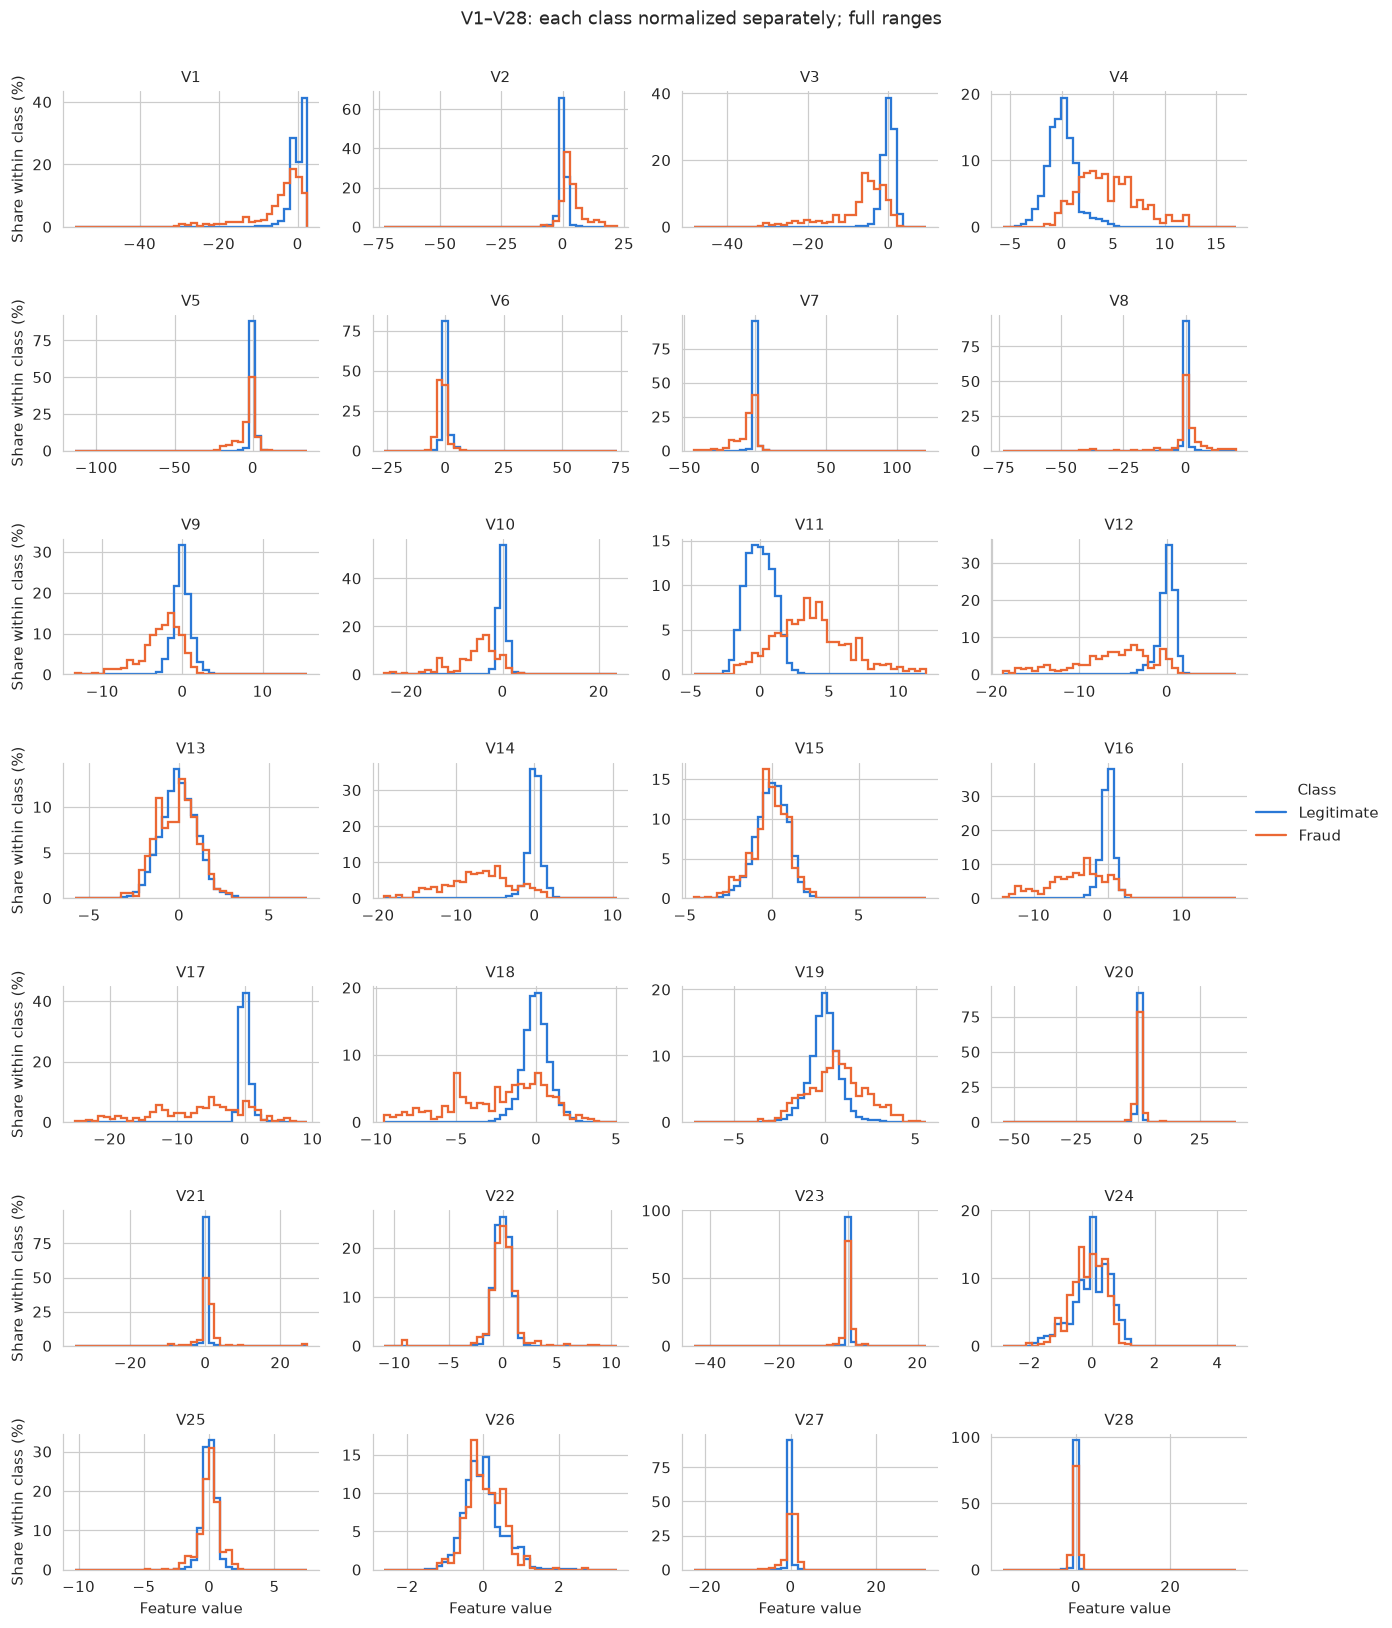

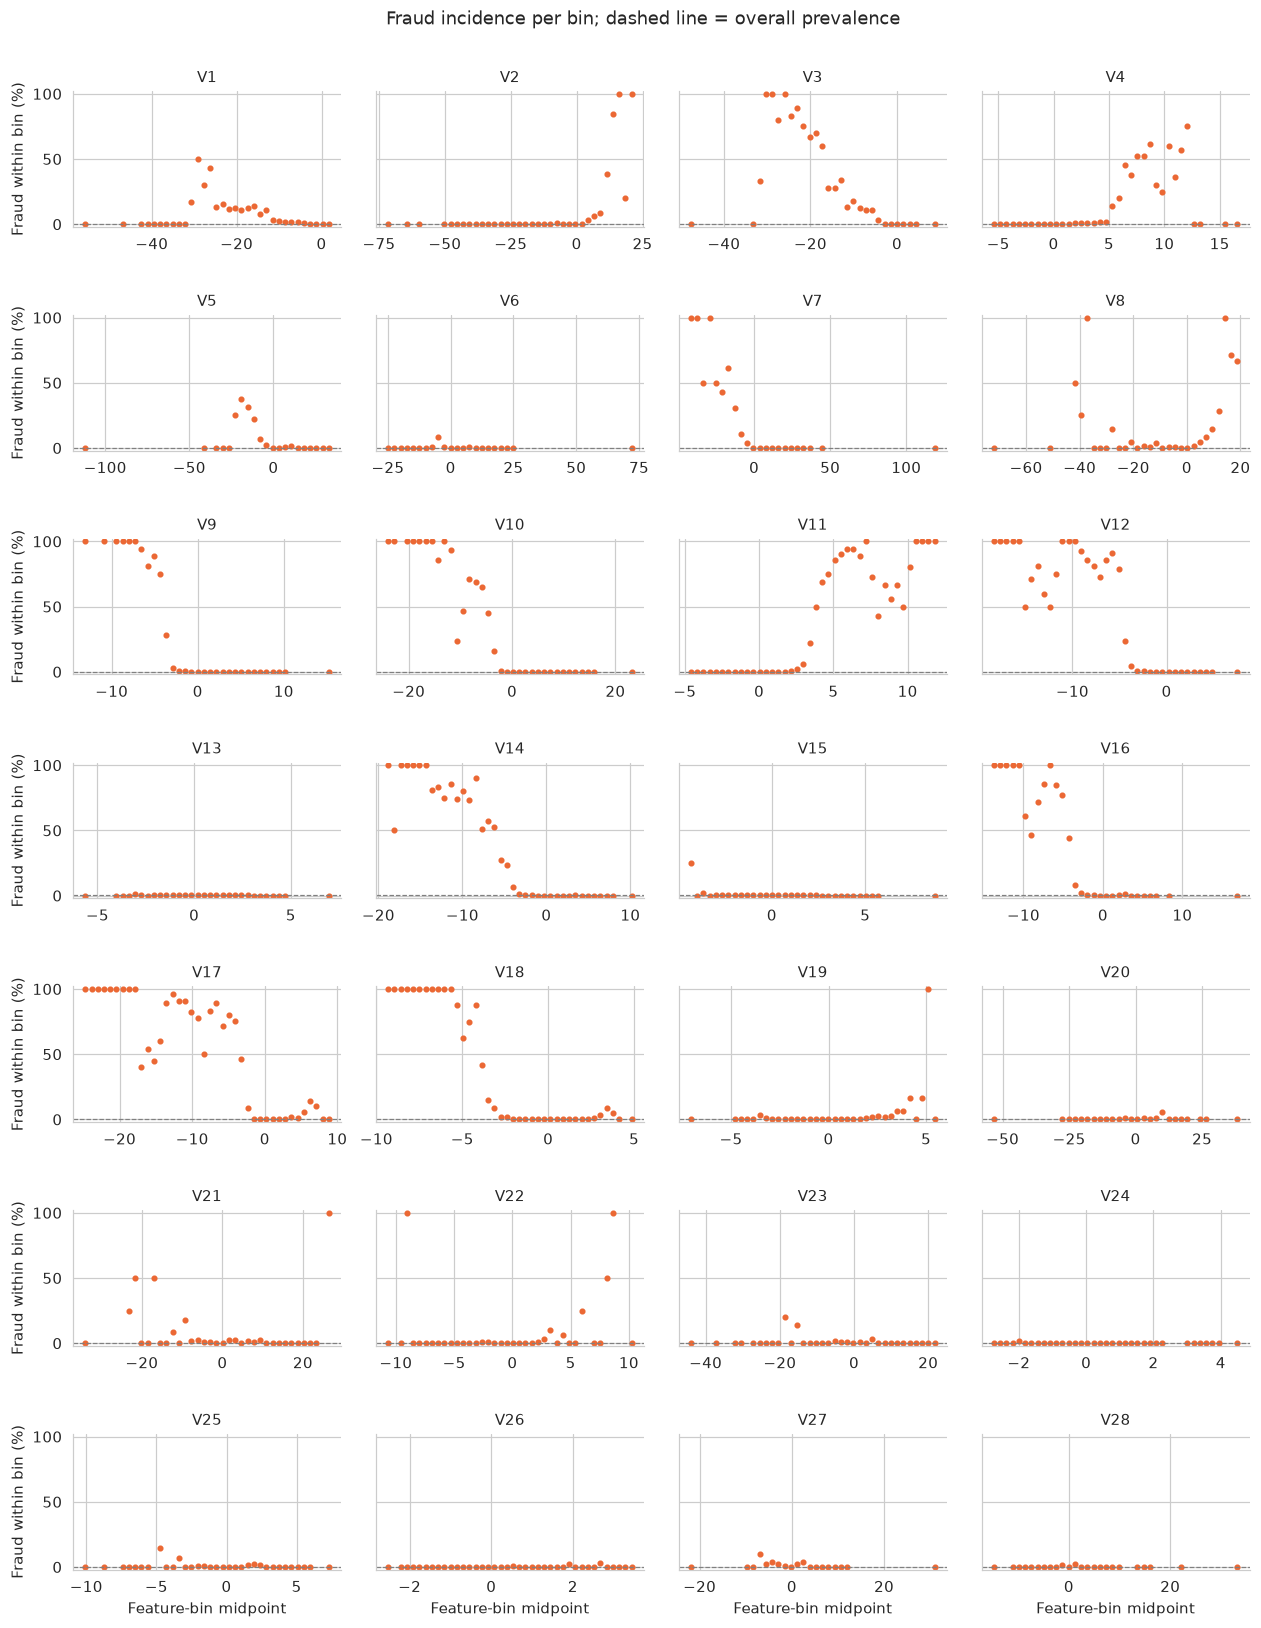

Distribution grid: each class sums to 100% in each feature panel.
Incidence grid: frauds / all records in the bin × 100; empty bins have no dot.
Sparse bins can show 100% from a single case. Inspect feature_incidence for counts.
Full ranges retained; PCA feature meanings are unknown. This is descriptive EDA, not final model evaluation.


In [ ]:
# Seaborn FacetGrid: full-data feature distributions and fraud incidence.
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

features = [f"V{i}" for i in range(1, 29)]
palette = {"Legitimate": "#2a78d6", "Fraud": "#eb6834"}
histograms, incidence = [], []
for feature in features:
    edges = np.histogram_bin_edges(df[feature], bins=40)
    total, _ = np.histogram(df[feature], bins=edges)
    fraud, _ = np.histogram(df.loc[df["Class"].eq(1), feature], bins=edges)
    assert total.sum() == len(df) and fraud.sum() == df["Class"].sum()
    for label, counts in [("Legitimate", total - fraud), ("Fraud", fraud)]:
        histograms.append(pd.DataFrame(dict(feature=feature, label=label, left=edges[:-1], right=edges[1:], count=counts, class_pct=100 * counts / counts.sum())))
    rate = np.divide(100.0 * fraud, total, out=np.full(total.shape, np.nan), where=total > 0)
    incidence.append(pd.DataFrame(dict(feature=feature, center=(edges[:-1] + edges[1:]) / 2, total=total, fraud=fraud, fraud_pct=rate)))
feature_histograms = pd.concat(histograms, ignore_index=True)
feature_incidence = pd.concat(incidence, ignore_index=True)

# Bin counts are exact, not sampled. Common edges are used for both classes.
def draw_distribution(data, color=None, label=None, **kwargs):
    edges = np.r_[data["left"].to_numpy(), data["right"].iloc[-1]]
    plt.stairs(data["class_pct"], edges, color=color, label=label, linewidth=1.5)

with sns.axes_style("whitegrid"):
    distribution_grid = sns.FacetGrid(feature_histograms, col="feature", col_order=features, col_wrap=4, hue="label", hue_order=list(palette), palette=palette, sharex=False, sharey=False, height=2.1, aspect=1.35)
    distribution_grid.map_dataframe(draw_distribution)
    distribution_grid.add_legend(title="Class")
    distribution_grid.set_titles("{col_name}")
    distribution_grid.set_axis_labels("Feature value", "Share within class (%)")
    distribution_grid.figure.subplots_adjust(top=0.94, hspace=0.65)
    distribution_grid.figure.suptitle("V1–V28: each class normalized separately; full ranges", y=0.99)
    plt.show()

# Incidence is P(fraud | bin), unlike the within-class distributions above.
# Dots avoid implying interpolation between sparsely populated bins.
def draw_incidence(data, color=None, **kwargs):
    plt.plot(data["center"], data["fraud_pct"], linestyle="none", marker=".", color="#eb6834", markersize=6)
    plt.axhline(df["Class"].mean() * 100, color="gray", linestyle="--", linewidth=0.8)

with sns.axes_style("whitegrid"):
    incidence_grid = sns.FacetGrid(feature_incidence, col="feature", col_order=features, col_wrap=4, sharex=False, sharey=True, height=2.1, aspect=1.35)
    incidence_grid.map_dataframe(draw_incidence)
    incidence_grid.set_titles("{col_name}")
    incidence_grid.set_axis_labels("Feature-bin midpoint", "Fraud within bin (%)")
    incidence_grid.set(ylim=(-2, 102))
    incidence_grid.figure.subplots_adjust(top=0.94, hspace=0.65)
    incidence_grid.figure.suptitle("Fraud incidence per bin; dashed line = overall prevalence", y=0.99)
    plt.show()

print("Distribution grid: each class sums to 100% in each feature panel.")
print("Incidence grid: frauds / all records in the bin × 100; empty bins have no dot.")
print("Sparse bins can show 100% from a single case. Inspect feature_incidence for counts.")
print("Full ranges retained; PCA feature meanings are unknown. This is descriptive EDA, not final model evaluation.")


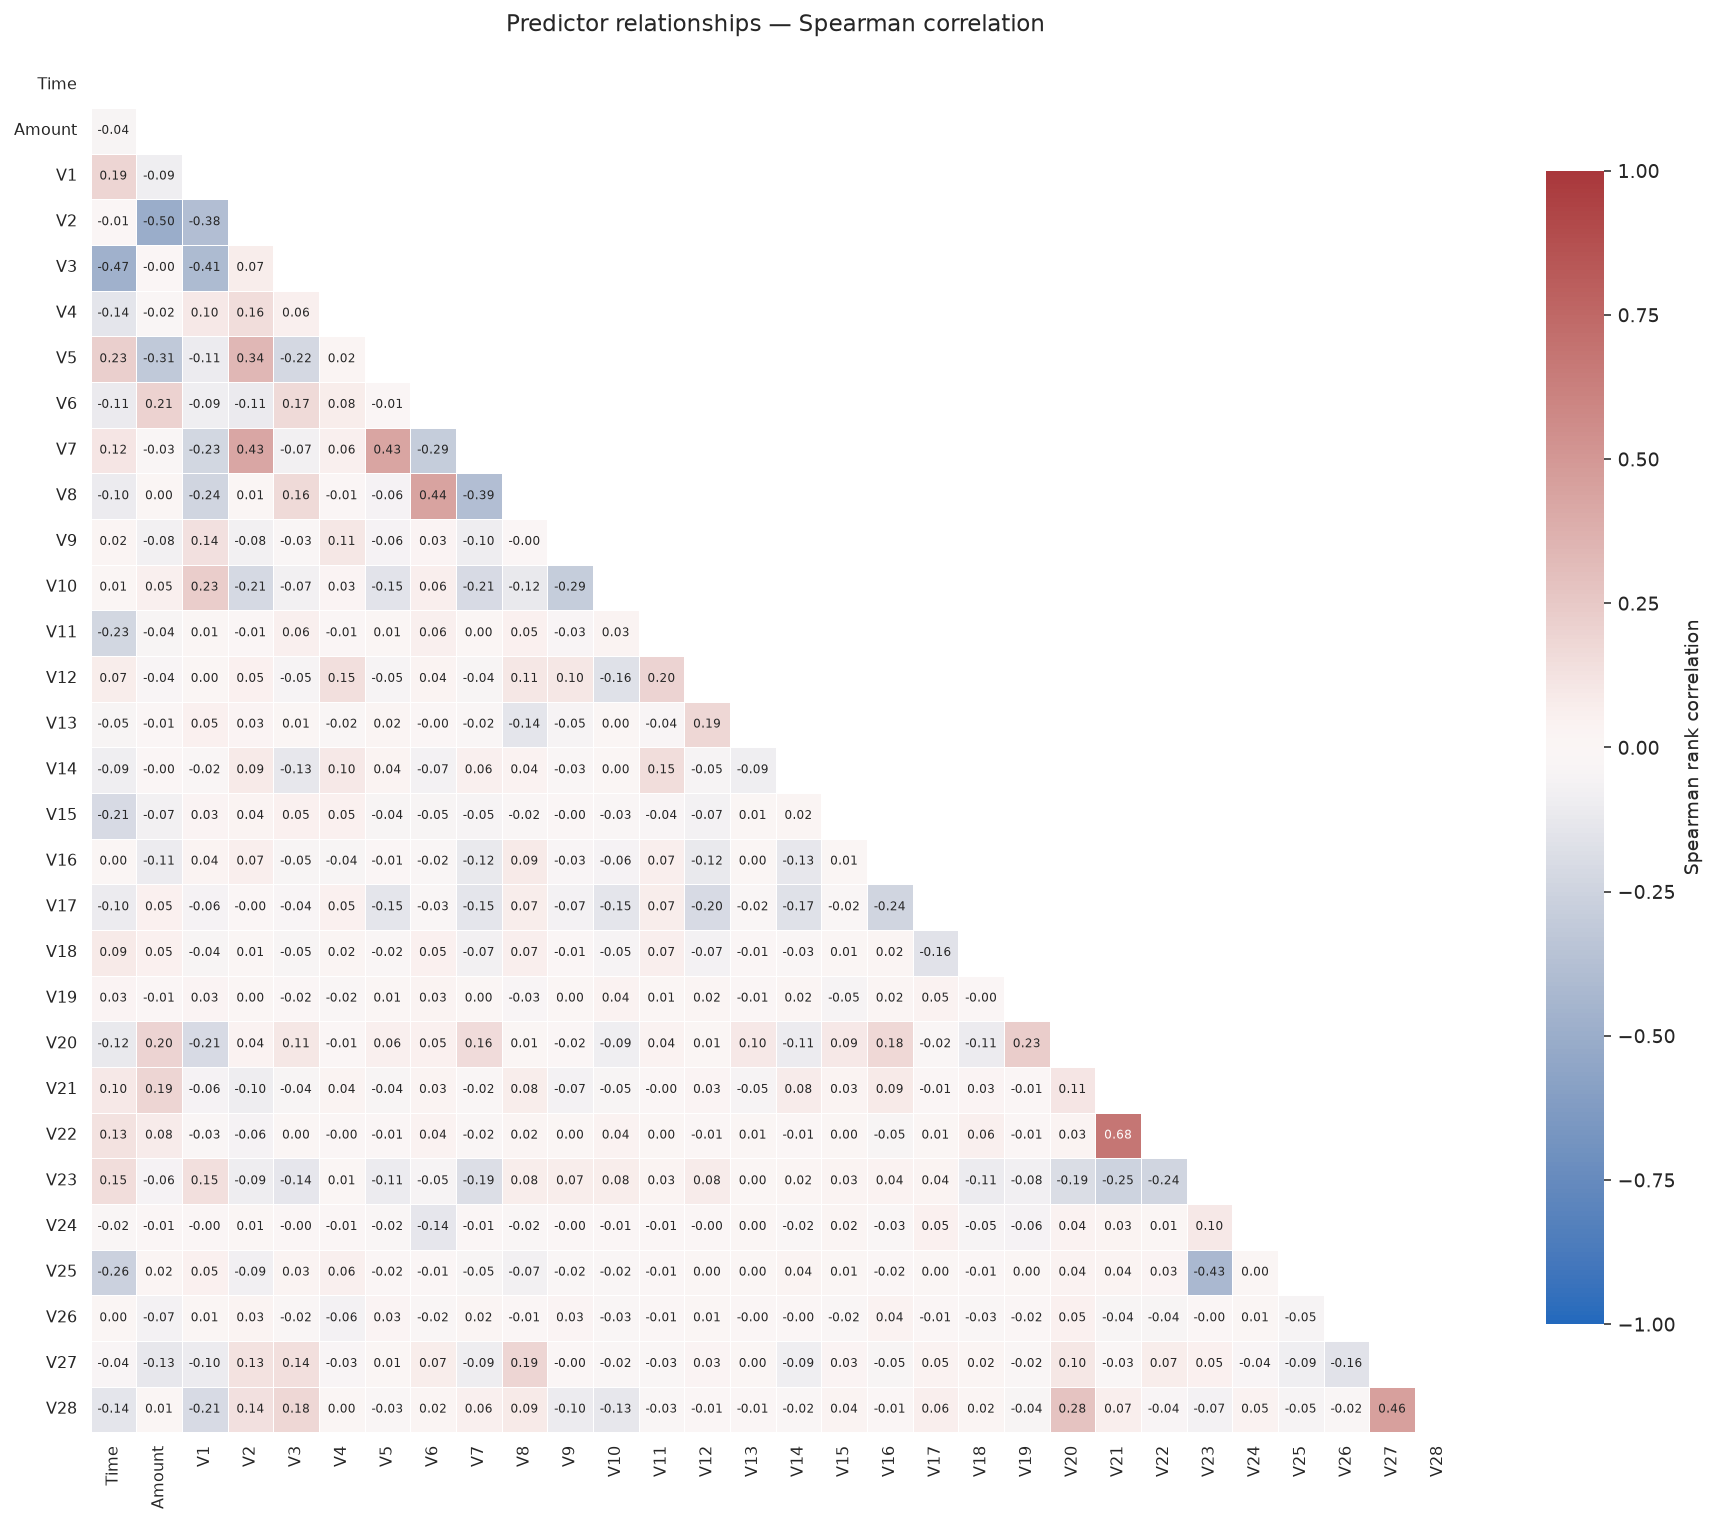

Strongest 15 predictor pairs (ranked by absolute correlation):
feature_1 feature_2  spearman_r  absolute_r
      V22       V21       0.677       0.677
       V2    Amount      -0.502       0.502
       V3      Time      -0.473       0.473
      V28       V27       0.458       0.458
       V8        V6       0.444       0.444
       V7        V5       0.432       0.432
       V7        V2       0.426       0.426
      V25       V23      -0.426       0.426
       V3        V1      -0.412       0.412
       V8        V7      -0.389       0.389
       V2        V1      -0.384       0.384
       V5        V2       0.343       0.343
       V5    Amount      -0.314       0.314
       V7        V6      -0.293       0.293
      V10        V9      -0.291       0.291
Pairs with |Spearman r| >= 0.5: 2 of 435


In [ ]:
# Relationships between predictors: full dataset; Class is intentionally excluded.
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

correlation_features = ["Time", "Amount"] + [f"V{i}" for i in range(1, 29)]
spearman_corr = df[correlation_features].corr(method="spearman")
upper_triangle = np.triu(np.ones(spearman_corr.shape, dtype=bool))

with sns.axes_style("white"):
    correlation_figure, correlation_axis = plt.subplots(figsize=(13, 11))
    sns.heatmap(spearman_corr, mask=upper_triangle, cmap="vlag", vmin=-1, vmax=1, center=0, square=True, annot=True, fmt=".2f", annot_kws={"fontsize": 6}, linewidths=0.3, cbar_kws={"label": "Spearman rank correlation", "shrink": 0.8}, ax=correlation_axis)
    correlation_axis.set_title("Predictor relationships — Spearman correlation", pad=16)
    correlation_axis.tick_params(axis="x", rotation=90, labelsize=8)
    correlation_axis.tick_params(axis="y", rotation=0, labelsize=8)
    correlation_figure.tight_layout()
    plt.show()

# Unique pairs only: no diagonal and no mirrored duplicates.
row_indices, column_indices = np.tril_indices(len(correlation_features), k=-1)
correlation_pairs = pd.DataFrame({"feature_1": np.array(correlation_features)[row_indices], "feature_2": np.array(correlation_features)[column_indices], "spearman_r": spearman_corr.to_numpy()[row_indices, column_indices]})
correlation_pairs["absolute_r"] = correlation_pairs["spearman_r"].abs()
correlation_pairs = correlation_pairs.sort_values("absolute_r", ascending=False, ignore_index=True)
print("Strongest 15 predictor pairs (ranked by absolute correlation):")
print(correlation_pairs.head(15).round(3).to_string(index=False))
print(f"Pairs with |Spearman r| >= 0.5: {(correlation_pairs['absolute_r'] >= 0.5).sum()} of {len(correlation_pairs)}")

# PCA's linear decorrelation does not guarantee zero rank correlation.
# Correlation is neither causation nor proof of redundancy; do not drop features automatically.
# This does not measure association with fraud: Class is excluded.
